# ECE1512 — Project B, Part 2: Learned Image Compression

Complete the marked `TODO` sections and run the notebook in order. Use the validation split to select model settings; evaluate the held-out test split only after selection.


**SSIM protocol:** RGB tensors in `[0,1]`, TorchMetrics Gaussian window 11×11, sigma 1.5, `data_range=1`. Compute one SSIM per image and average equally, matching the restoration project. SSIM, PSNR, and file bpp describe different properties; report all three. Historical executed notebooks retain their original outputs until rerun.


## Step 0 — Setup and data

Install dependencies if needed:

```bash
python -m pip install torch torchmetrics numpy pillow matplotlib notebook
```

Doenload  images from 
https://huggingface.co/datasets/LeonYe/ADPPatches

Place the `data_1um_bicubic` image folder in the parent directory of this notebook, as in the original project, or specify a custom path using `DATA_ROOT` below.

In [1]:
from pathlib import Path
import sys, json, copy, math, io
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == 'instructor':
    PROJECT_DIR = PROJECT_DIR.parent
if (PROJECT_DIR / 'dnn_compression_notebook').is_dir():
    PROJECT_DIR = PROJECT_DIR / 'dnn_compression_notebook'
assert (PROJECT_DIR / 'model.py').is_file(), 'Set PROJECT_DIR to the helper folder'
sys.path.insert(0, str(PROJECT_DIR))
DATA_ROOT = PROJECT_DIR.parent / 'data_1um_bicubic'
OUTPUT_ROOT = PROJECT_DIR / 'runs'
from data import seed_everything, split_images, make_loaders
from model import CompressionModel
from engine import fit, evaluate, load_checkpoint
from checks import check_soft_quantize, check_pipeline
from codec import compress, decompress
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
print('Device:', DEVICE, '| PyTorch:', torch.__version__)

c:\Users\anest\anaconda3\envs\torch\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | PyTorch: 2.6.0+cu126


## 2. Configuration

Fixed held-out test crops: 256
Images used for training/validation: {'train': 1024, 'val': 128}
Input: (32, 3, 64, 64)


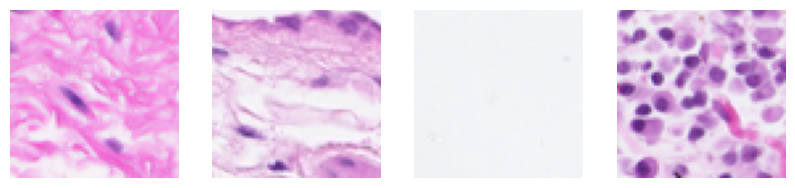

In [2]:
MODE = 'larger'
SEED = 1512
DATA_CONFIG = dict(crop_size=64, batch_size=32)
MODEL_CONFIG = {'width': 64, 'latent_dim': 16, 'levels': 1, 'codebook_size': 256, 'straight_through': True}
TRAIN_CONFIG = dict(epochs=40, lr=2e-4, rate_weight=1e-4,
                    temperature_start=0.05, temperature_end=0.01)
LIMITS = dict(train=1024, val=128, test=128)
seed_everything(SEED)
SPLIT_MANIFEST = OUTPUT_ROOT / 'shared_data_splits.json'
splits = split_images(DATA_ROOT, SPLIT_MANIFEST, seed=SEED)
loaders = make_loaders(splits, seed=SEED, limits=LIMITS, **DATA_CONFIG)
from data import ImageDataset
from torch.utils.data import DataLoader
all_test_paths = make_loaders(splits, seed=SEED, limits=None, **DATA_CONFIG)['test'].dataset.paths
loaders['test'] = DataLoader(ImageDataset(all_test_paths[128:384], crop_size=64, train=False),
                            batch_size=32, shuffle=False)
print('Fixed held-out test crops:', len(loaders['test'].dataset))
print('Images used for training/validation:', {s: len(loaders[s].dataset) for s in ('train','val')})
x = next(iter(loaders['train']))
print('Input:', tuple(x.shape))
fig, axes = plt.subplots(1,4,figsize=(10,3))
for ax, image in zip(axes,x[:4]):
    ax.imshow(image.permute(1,2,0)); ax.axis('off')
plt.show()


## Step 2 — Implement soft vector quantization

The encoder returns `z: [B,D,h,w]`. The helper rearranges it to `flat: [N,D]`, where `N=Bhw`. The trainable codebook is `codebook: [K,D]`.

For each latent vector $z_i$ and codeword $e_k$:

$$d_{ik}=\|z_i-e_k\|_2^2=\|z_i\|^2+\|e_k\|^2-2z_i^Te_k,$$
$$p_{ik}=\frac{\exp(-d_{ik}/\tau)}{\sum_j\exp(-d_{ij}/\tau)},\qquad \widetilde z_i=\sum_k p_{ik} e_k.$$

Complete TODO 2A–2C below. Use matrix multiplication for distances to avoid allocating `[N,K,D]`. Normalize across **codewords**, the last dimension. Use a numerically stable softmax. Do not detach, convert to NumPy, round, or take argmin in this soft path. Return `(soft_vectors, probabilities)`.

**Questions:** Why does smaller temperature approach nearest-neighbor quantization? What happens for large temperature? Why is a weighted average of codeword *indices* not the same as a weighted average of codeword *vectors*?

In [3]:
def TODO(hint):
    raise NotImplementedError('Complete the student exercise: ' + hint)

def soft_quantize(flat, codebook, temperature):
    """
    Args:
        flat: [N, D] latent vectors
        codebook: [K, D] codewords
        temperature: positive scalar

    Returns:
        soft_vectors: [N, D]
        probabilities: [N, K]
    """
    if temperature <= 0:
        raise ValueError("temperature must be positive")

    # TODO 1: Compute squared Euclidean distances [N, K].
    distances = (flat.square().sum(dim=1, keepdim=True) + codebook.square().sum(dim=1).unsqueeze(0) - 2.0 * (flat @ codebook.T)) # .square() squares each element then .sum(dim=1) adds the squared elements in each vector

    # TODO 2: Compute soft assignment probabilities [N, K].
    probabilities = torch.softmax(-distances / temperature, dim=-1) # convert distances into probabilities so that closer codebook vectors receive larger weights
    # TODO 3: Compute weighted codebook vectors [N, D].
    soft_vectors = probabilities @ codebook # we construct a new latent vector as a weighted average of the codebook vectors
    
    return soft_vectors, probabilities

## Step 3 — Check values, temperature behavior, and gradients

These checks test known distances, normalization, cold/hot limits, finite-difference gradients, and the complete model. A shape check alone is insufficient: a detached tensor can have the correct shape while preventing the encoder from learning.

During evaluation, the helper selects the closest codeword and decodes its vector. It never transmits the soft mixture. A test also encodes and decodes a non-square image whose dimensions are not divisible by the downsampling factor.

In [4]:
check_soft_quantize(soft_quantize)
check_pipeline(soft_quantize)
seed_everything(SEED)
model = CompressionModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
print('Trainable parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
with torch.no_grad():
    latent = model.encode(x[:1].to(DEVICE))
print('Latent shape:', tuple(latent.shape))
print('Assignment matrix elements per batch:', DATA_CONFIG['batch_size'] * latent.shape[-2] * latent.shape[-1] * MODEL_CONFIG['codebook_size'])

Soft quantization: shape, values, temperature, and gradients passed.
End-to-end gradients and odd-size bitstream round trip passed.
Trainable parameters: 195,987
Latent shape: (1, 16, 32, 32)
Assignment matrix elements per batch: 8388608


## PSNR and SSIM implementations

Compute one value per image for RGB tensors in `[0,1]`. These functions are used throughout validation, testing, JPEG comparison, and visualization.


In [5]:
import torch.nn.functional as F
def _metric_inputs(pred, target):
    """Validate matching [B,3,H,W] RGB tensors and compute in float32."""
    if pred.shape != target.shape or pred.ndim != 4 or pred.shape[1] != 3:
        raise ValueError('Expected matching [B,3,H,W] RGB tensors')
    if pred.device != target.device:
        raise ValueError('Prediction and target must be on the same device')
    return pred.float(), target.float()


def psnr_per_image(pred, target):
    """Return [B] PSNR in dB for RGB tensors with data range [0,1].

    Average squared error over channels and pixels independently per image.
    The 1e-12 MSE floor gives 120 dB for identical images.
    """
    # TODO
    pred, target = _metric_inputs(pred, target)

    # Compute MSE separately for each image
    mse = ((pred - target) ** 2).mean(dim=(1, 2, 3))

    # Prevent log10(0)
    mse = mse.clamp_min(1e-12)

    # PSNR for data_range = 1
    return -10.0 * torch.log10(mse)


def ssim_per_image(pred, target):
    """Return [B] RGB SSIM: Gaussian 11x11, sigma 1.5, data_range=1.

    Population moments are computed independently per channel. Exclude the
    five-pixel border before averaging, matching the TorchMetrics protocol.
    """
    

    pred, target = _metric_inputs(pred, target)
    if min(pred.shape[-2:]) < 11:
        raise ValueError('SSIM requires images at least 11x11 pixels')
    # TODO
    # Step 1: Construct an 11x11 Gaussian kernel
    coords = torch.arange(-5, 6, dtype=pred.dtype, device=pred.device)

    gaussian = torch.exp(-(coords ** 2) / (2 * 1.5 ** 2))
    gaussian = gaussian / gaussian.sum()

    kernel = gaussian[:, None] * gaussian[None, :]
    kernel = kernel.expand(3, 1, 11, 11).contiguous()

    # Step 2: Apply Gaussian filtering independently to RGB
    def filter_rgb(x):
        return F.conv2d(x, kernel, groups=3)

    # Step 3: Compute local means
    mu_x = filter_rgb(pred)
    mu_y = filter_rgb(target)

    mu_x_sq = mu_x ** 2
    mu_y_sq = mu_y ** 2
    mu_xy = mu_x * mu_y

    # Step 4: Compute population variances and covariance
    sigma_x_sq = (filter_rgb(pred ** 2) - mu_x_sq).clamp_min(0.0)

    sigma_y_sq = (filter_rgb(target ** 2) - mu_y_sq).clamp_min(0.0)

    sigma_xy = filter_rgb(pred * target) - mu_xy

    # Step 5: SSIM stability constants
    C1 = 0.01 ** 2
    C2 = 0.03 ** 2

    # Step 6: Compute SSIM map
    numerator = ((2 * mu_xy + C1) *(2 * sigma_xy + C2))

    denominator = ((mu_x_sq + mu_y_sq + C1) *(sigma_x_sq + sigma_y_sq + C2))

    ssim_map = numerator / denominator

    # Step 7: Average channels and valid spatial positions
    return ssim_map.mean(dim=(1, 2, 3))


In [6]:
# Reference functions are used only to check your implementation.
from metrics import ssim_per_image as reference_ssim
from functools import partial
import engine as training_engine

metric_generator = torch.Generator().manual_seed(1512)
metric_target = torch.rand(2, 3, 24, 28, generator=metric_generator, device='cpu').to(DEVICE)
metric_pred = (0.8 * metric_target + 0.1).clamp(0, 1)
expected_mse = (metric_pred - metric_target).square().flatten(1).mean(1)
for pred, target in [(metric_target, metric_target), (metric_pred, metric_target),
                     (torch.zeros_like(metric_target), torch.ones_like(metric_target))]:
    actual_psnr = psnr_per_image(pred, target)
    actual_ssim = ssim_per_image(pred, target)
    assert actual_psnr.shape == actual_ssim.shape == (2,)
    assert actual_psnr.device == actual_ssim.device == target.device
    expected_psnr = -10 * (pred - target).square().flatten(1).mean(1).clamp_min(1e-12).log10()
    torch.testing.assert_close(actual_psnr, expected_psnr)
    torch.testing.assert_close(actual_ssim, reference_ssim(pred, target), rtol=1e-4, atol=1e-5)
# Different errors in one batch catch accidentally averaging before log10.
mixed_pred = torch.stack([metric_target[0], metric_pred[1]])
torch.testing.assert_close(psnr_per_image(mixed_pred, metric_target),
                          torch.stack([expected_mse.new_tensor(120.), -10 * expected_mse[1].log10()]))

# Bind the student implementations to all evaluation and training calls below.
student_metrics = dict(psnr_fn=psnr_per_image, ssim_fn=ssim_per_image)
evaluate = partial(training_engine.evaluate, **student_metrics)
fit = partial(training_engine.fit, **student_metrics)

## Step 4 — Understand the provided end-to-end objective

The learned categorical prior is $r_k=\mathrm{softmax}(a)_k$. With $H,W$ measured in input pixels:

$$R_{soft}=\frac{\sum_{i,k}p_{ik}[-\log_2 r_k]}{BHW},\qquad L=\mathrm{MSE}(x,\widehat x)+\lambda R_{soft}.$$

All encoder, decoder, codebook, and prior parameters are optimized jointly with Adam. MSE is measured on `[0,1]` RGB; its scale matters when choosing $\lambda$. The temperature decreases geometrically from the configured start to end value. Gradient clipping limits the total norm to 1.

At validation/test time, $R_{hard}=\sum_i-\log_2 r_{k_i}/(BHW)$ uses hard nearest-neighbor indices. We choose the checkpoint with the lowest **hard validation** `MSE + rate_weight × estimated_bpp`. PSNR is computed per image and then averaged. Neither this rate estimate nor codebook entropy is a measured file size.

**Questions:** Which parameters receive gradients from reconstruction and rate? Why can soft-training quality differ from hard-evaluation quality? Why does increasing the rate penalty tend to trade fidelity for predictability? What does a collapsed codebook look like?

## Step 5 — Train the model


In [7]:
from datetime import datetime
import csv
sys.path.insert(0, str(PROJECT_DIR / 'instructor'))
from warm_start import warm_start
USE_WARM_START = True
REUSE_CHECKPOINT = None  # Optional path to a completed run's best.pt; None trains from scratch.
seed_everything(SEED)
loaders = make_loaders(splits, seed=SEED, limits=LIMITS, **DATA_CONFIG)
from data import ImageDataset
from torch.utils.data import DataLoader
all_test_paths = make_loaders(splits, seed=SEED, limits=None, **DATA_CONFIG)['test'].dataset.paths
loaders['test'] = DataLoader(ImageDataset(all_test_paths[128:384], crop_size=64, train=False),
                            batch_size=32, shuffle=False)
print('Fixed held-out test crops:', len(loaders['test'].dataset))
if REUSE_CHECKPOINT is None:
    RUN_DIR = OUTPUT_ROOT / ('solution_' + MODE + '_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    model = CompressionModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
    initialization = None
    if USE_WARM_START:
        initialization = warm_start(model, loaders['train'], DEVICE, epochs=8, max_vectors=32768)
        TRAIN_CONFIG.update(temperature_start=initialization['temperature_start'],
                            temperature_end=initialization['temperature_start'] * 0.2)
        print('Training-only initialization:', initialization)
    model, history = fit(model, loaders, TRAIN_CONFIG, RUN_DIR, DEVICE)
    if initialization is not None:
        (RUN_DIR / 'warmup.json').write_text(json.dumps(initialization, indent=2))
else:
    RUN_DIR = Path(REUSE_CHECKPOINT).resolve().parent
    model, saved_checkpoint = load_checkpoint(REUSE_CHECKPOINT, soft_quantize, DEVICE)
    assert model.config == MODEL_CONFIG, 'Reuse a checkpoint with the displayed architecture'
    TRAIN_CONFIG = saved_checkpoint['train_config']
    with (RUN_DIR / 'history.csv').open() as handle:
        history = [{k: float(v) for k,v in row.items()} for row in csv.DictReader(handle)]
    print('Loaded completed training run:', REUSE_CHECKPOINT)
    if (RUN_DIR / 'warmup.json').exists():
        print('Training-only initialization:', (RUN_DIR / 'warmup.json').read_text())
    print('Best validation:', saved_checkpoint['validation'])
protocol = dict(seed=SEED, mode=MODE, data_root=str(DATA_ROOT.resolve()),
                manifest=str(SPLIT_MANIFEST.resolve()), data_config=DATA_CONFIG, limits=LIMITS,
                used_paths={s: [str(p.relative_to(DATA_ROOT)) for p in loader.dataset.paths]
                            for s, loader in loaders.items()})
(RUN_DIR / 'data_protocol.json').write_text(json.dumps(protocol, indent=2))
print('Saved:', RUN_DIR)


Fixed held-out test crops: 256
Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00672
Continuous warmup 4/8: training MSE=0.00364
Continuous warmup 5/8: training MSE=0.00247
Continuous warmup 6/8: training MSE=0.00221
Continuous warmup 7/8: training MSE=0.00204
Continuous warmup 8/8: training MSE=0.00175
Training-only initialization: {'warmup_epochs': 8, 'warmup_seconds': 29.469370800012257, 'training_mse': [0.036513080063741654, 0.010657911814632826, 0.006722268874000292, 0.003643475254648365, 0.002473512060532812, 0.002208779456850607, 0.0020417941668711137, 0.001746723570249742], 'initialization_vectors': 32768, 'temperature_start': 0.030189750716090202, 'temperature_end': 0.0030189750716090205}
Epoch 1/40: train=0.00251, hard val PSNR=27.97, SSIM=0.8598, estimated bpp=1.9995
Epoch 2/40: train=0.00211, hard val PSNR=28.41, SSIM=0.8679, estimated bpp=1.9981
Epoch 3/40: train=0.00199, hard val PSNR=28.72, SSI

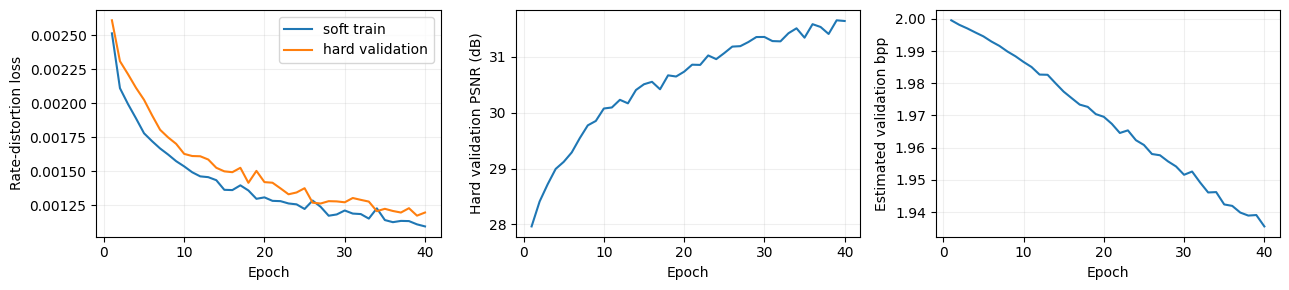

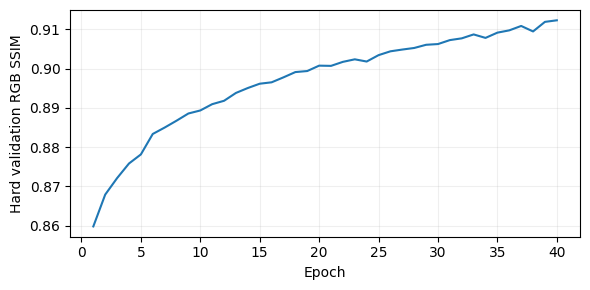

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
epochs = [r['epoch'] for r in history]
axes[0].plot(epochs, [r['train_loss'] for r in history], label='soft train')
axes[0].plot(epochs, [r['val_loss'] for r in history], label='hard validation')
axes[0].set_ylabel('Rate-distortion loss'); axes[0].legend()
axes[1].plot(epochs, [r['val_psnr'] for r in history]); axes[1].set_ylabel('Hard validation PSNR (dB)')
axes[2].plot(epochs, [r['val_estimated_bpp'] for r in history]); axes[2].set_ylabel('Estimated validation bpp')
for ax in axes: ax.set_xlabel('Epoch'); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(RUN_DIR / 'learning_curves.png', dpi=160); plt.show()
if all("val_ssim" in row for row in history):
    plt.figure(figsize=(6,3))
    plt.plot(epochs, [row["val_ssim"] for row in history])
    plt.xlabel("Epoch"); plt.ylabel("Hard validation RGB SSIM"); plt.grid(alpha=.2)
    plt.tight_layout(); plt.savefig(RUN_DIR / "validation_ssim.png", dpi=160); plt.show()


## Step 6 — Tune on validation data

Change one factor at a time: temperature end (`0.02, 0.05, 0.2`), rate weight (`0, 0.001, 0.01`), codebook size (`32, 64, 128`), width (`16, 24, 32`), latent dimension (`4, 8, 16`), or levels (`2, 3`). Keep the split, crop size, sample budget, seed, and epoch budget fixed within a comparison.

Optional `straight_through=True` uses hard vectors in the forward pass and soft-mixture gradients in the backward pass. Compare this to the default fully soft training path as a research extension.

Run at least three configurations for your report. The optional cell below runs rate-weight experiments and plots validation PSNR against **estimated** rate. Choose the desired rate/quality tradeoff from validation; losses with different rate weights are not directly comparable. Each fit uses its own rate weight for epoch selection.

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00672
Continuous warmup 4/8: training MSE=0.00364
Continuous warmup 5/8: training MSE=0.00247
Continuous warmup 6/8: training MSE=0.00221
Continuous warmup 7/8: training MSE=0.00204
Continuous warmup 8/8: training MSE=0.00174
Epoch 1/40: train=0.00230, hard val PSNR=27.98, SSIM=0.8600, estimated bpp=2.0000
Epoch 2/40: train=0.00191, hard val PSNR=28.42, SSIM=0.8677, estimated bpp=2.0000
Epoch 3/40: train=0.00179, hard val PSNR=28.71, SSIM=0.8721, estimated bpp=2.0000
Epoch 4/40: train=0.00169, hard val PSNR=28.95, SSIM=0.8758, estimated bpp=2.0000
Epoch 5/40: train=0.00157, hard val PSNR=29.16, SSIM=0.8794, estimated bpp=2.0000
Epoch 6/40: train=0.00151, hard val PSNR=29.46, SSIM=0.8829, estimated bpp=2.0000
Epoch 7/40: train=0.00145, hard val PSNR=29.55, SSIM=0.8852, estimated bpp=2.0000
Epoch 8/40: train=0.00143, hard val PSNR=29.79, SSIM=0.8867, estimated bpp

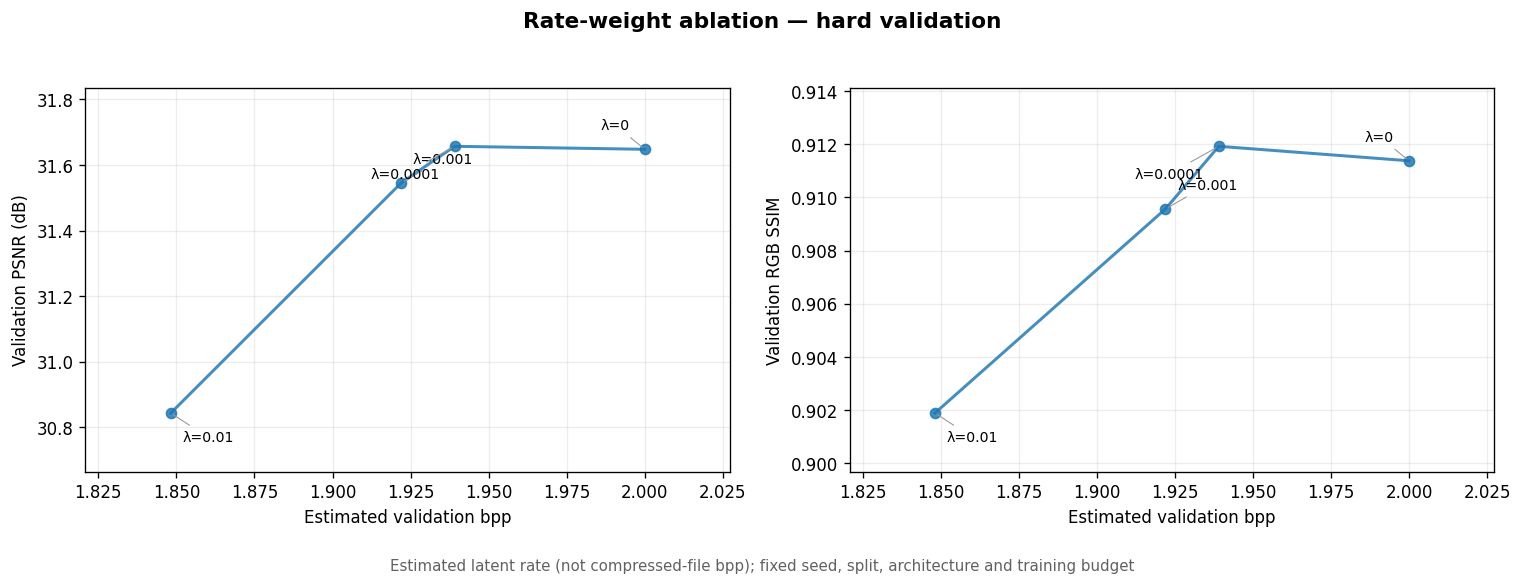

In [9]:
RUN_SWEEP = True  # Enable after the baseline works; costs three training runs.
validation_runs = []
if RUN_SWEEP:
    for rate_weight in (0.0, 0.001, 0.01):
        seed_everything(SEED)
        candidate_config = dict(TRAIN_CONFIG, rate_weight=rate_weight)
        candidate_loaders = make_loaders(splits, seed=SEED, limits=LIMITS, **DATA_CONFIG)
        candidate = CompressionModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
        destination = OUTPUT_ROOT / ('sweep_' + str(rate_weight) + '_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
        if USE_WARM_START:
            init = warm_start(candidate, candidate_loaders['train'], DEVICE, epochs=8, max_vectors=32768)
            candidate_config.update(temperature_start=init['temperature_start'], temperature_end=init['temperature_start']*.2)
        candidate, _ = fit(candidate, candidate_loaders, candidate_config, destination, DEVICE)
        (destination / 'data_protocol.json').write_text(json.dumps(protocol, indent=2))
        metrics = evaluate(candidate, candidate_loaders['val'], DEVICE, rate_weight)
        validation_runs.append(dict(rate_weight=rate_weight, checkpoint=str(destination/'best.pt'), **metrics))
        del candidate
    print(json.dumps(validation_runs, indent=2))
    (RUN_DIR / 'validation_sweep.json').write_text(json.dumps(validation_runs, indent=2))
    # plt.scatter([r['estimated_bpp'] for r in validation_runs], [r['psnr'] for r in validation_runs])
    # for r in validation_runs: plt.annotate(str(r['rate_weight']), (r['estimated_bpp'], r['psnr']))
    # plt.xlabel('Estimated validation bpp'); plt.ylabel('Validation PSNR (dB)'); 
    
    # plt.grid(alpha=.2)
    # plt.tight_layout()
    # plt.savefig(RUN_DIR / 'validation_rate_sweep.png', dpi=160)
    # plt.show()

    # IMPROVED PLOTTING — PSNR AND SSIM
    # Training logic above is unchanged.
    # ==========================================================

    baseline_state = torch.load(RUN_DIR / 'best.pt',map_location='cpu', weights_only=True)
    baseline_metrics = baseline_state['validation']
    baseline_weight = baseline_state['train_config']['rate_weight']
    rate_plot_runs = validation_runs + [dict(rate_weight=baseline_weight,**baseline_metrics)]
    rate_plot_runs = sorted(rate_plot_runs, key=lambda r: r['estimated_bpp'])
    fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8), dpi=120)
    for ax, metric, ylabel in zip(axes,('psnr', 'ssim'),('Validation PSNR (dB)', 'Validation RGB SSIM')):
        ax.plot([r['estimated_bpp'] for r in rate_plot_runs],[r[metric] for r in rate_plot_runs],'o-',color='tab:blue',lw=1.8, ms=6, alpha=0.83)
        for i, r in enumerate(rate_plot_runs):
            is_baseline = r.get('is_baseline', False)
            if is_baseline:
                ax.scatter(r['estimated_bpp'], r[metric],marker='*',s=155,color='tab:orange',edgecolor='white',linewidth=0.8,zorder=5)
            label = f"λ={r['rate_weight']:g}"
            if is_baseline:
                label += ' (baseline)'

            dx, dy = [(7, -17), (7, 12),(-9, -19), (-9, 12)][i % 4]
            ax.annotate(label,(r['estimated_bpp'], r[metric]), xytext=(dx, dy),textcoords='offset points',ha='left' if dx >= 0 else 'right',fontsize=8.5,arrowprops=dict(arrowstyle='-',color='0.6',lw=0.65))
        ax.set_xlabel('Estimated validation bpp')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.22)
        ax.margins(x=0.18, y=0.22)

    fig.suptitle('Rate-weight ablation — hard validation',fontsize=13,weight='bold')
    fig.text(0.5, 0.01,'Estimated latent rate (not compressed-file bpp); ''fixed seed, split, architecture and training budget',ha='center',fontsize=9,color='0.38')
    fig.tight_layout(rect=(0, 0.055, 1, 0.95))
    fig.savefig(RUN_DIR / 'validation_rate_sweep.png',dpi=200, bbox_inches='tight')
    fig.savefig(RUN_DIR / 'validation_rate_sweep.pdf',bbox_inches='tight')
    plt.show()

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00672
Continuous warmup 4/8: training MSE=0.00364
Continuous warmup 5/8: training MSE=0.00247
Continuous warmup 6/8: training MSE=0.00221
Continuous warmup 7/8: training MSE=0.00204
Continuous warmup 8/8: training MSE=0.00175
Epoch 1/40: train=0.00333, hard val PSNR=26.53, SSIM=0.8226, estimated bpp=1.2489
Epoch 2/40: train=0.00285, hard val PSNR=26.77, SSIM=0.8323, estimated bpp=1.2474
Epoch 3/40: train=0.00271, hard val PSNR=26.94, SSIM=0.8350, estimated bpp=1.2457
Epoch 4/40: train=0.00258, hard val PSNR=27.21, SSIM=0.8435, estimated bpp=1.2444
Epoch 5/40: train=0.00241, hard val PSNR=27.30, SSIM=0.8482, estimated bpp=1.2430
Epoch 6/40: train=0.00239, hard val PSNR=27.61, SSIM=0.8506, estimated bpp=1.2413
Epoch 7/40: train=0.00233, hard val PSNR=27.80, SSIM=0.8526, estimated bpp=1.2399
Epoch 8/40: train=0.00230, hard val PSNR=27.75, SSIM=0.8557, estimated bpp

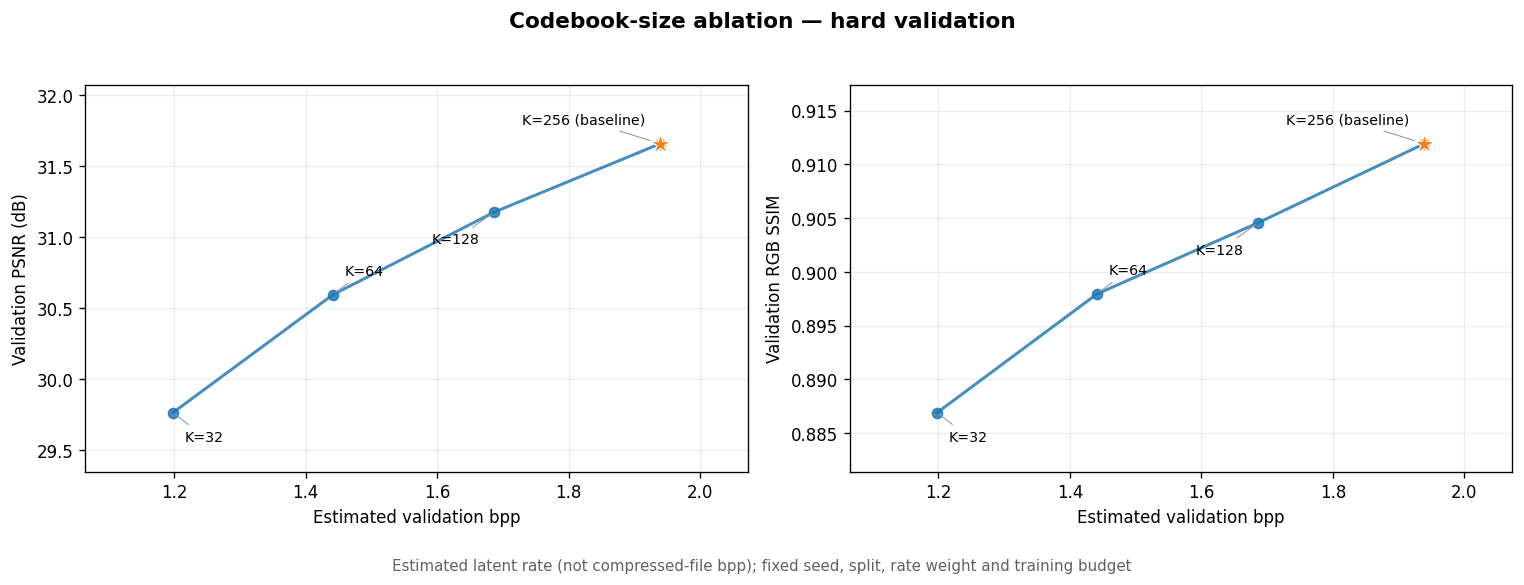

In [10]:
### NEW ADDED BY ME !!!
# QUESTION 4 — ABLATION 2: CODEBOOK SIZE

RUN_CODEBOOK_SWEEP = True
codebook_runs = []

if RUN_CODEBOOK_SWEEP:
    for k in (32, 64, 128):  # K=256 is our existing baseline
        seed_everything(SEED)
        candidate_config = dict(TRAIN_CONFIG)
        candidate_model_config = dict(MODEL_CONFIG, codebook_size=k)
        candidate_loaders = make_loaders(splits, seed=SEED, limits=LIMITS, **DATA_CONFIG)
        candidate = CompressionModel(soft_quantize, **candidate_model_config).to(DEVICE)
        destination = OUTPUT_ROOT / ('codebook_k' + str(k) + '_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
        if USE_WARM_START:
            init = warm_start(candidate,candidate_loaders['train'],DEVICE,epochs=8,max_vectors=32768)
            candidate_config.update(temperature_start=init['temperature_start'],temperature_end=init['temperature_start'] * .2)
        candidate, _ = fit(candidate, candidate_loaders,candidate_config, destination, DEVICE)
        if USE_WARM_START:
            (destination / 'warmup.json').write_text(json.dumps(init, indent=2) )

        (destination / 'data_protocol.json').write_text(json.dumps(protocol, indent=2))
        metrics = evaluate(candidate,candidate_loaders['val'],DEVICE,candidate_config['rate_weight'])
        codebook_runs.append(dict(codebook_size=k,rate_weight=candidate_config['rate_weight'],checkpoint=str(destination / 'best.pt'),**metrics ))
        print(f'K={k}: ' f'validation PSNR={metrics["psnr"]:.2f}, ' f'SSIM={metrics["ssim"]:.4f}, 'f'estimated BPP={metrics["estimated_bpp"]:.3f}')
        del candidate

    print(json.dumps(codebook_runs, indent=2))
    (RUN_DIR / 'codebook_sweep.json').write_text(json.dumps(codebook_runs, indent=2))
    print('Saved:', RUN_DIR / 'codebook_sweep.json')

    # ==========================================================
    # IMPROVED PLOTTING — PSNR AND SSIM
    # Includes the original K=256 baseline.
    # ==========================================================

    baseline_state = torch.load(RUN_DIR / 'best.pt',map_location='cpu',weights_only=True)
    baseline_metrics = baseline_state['validation']
    plot_runs = codebook_runs + [dict(codebook_size=MODEL_CONFIG['codebook_size'],is_baseline=True,**baseline_metrics )]
    plot_runs = sorted(plot_runs,key=lambda r: r['estimated_bpp'])
    fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8), dpi=120)
    for ax, metric, ylabel in zip(axes,('psnr', 'ssim'),('Validation PSNR (dB)', 'Validation RGB SSIM')):
        ax.plot([r['estimated_bpp'] for r in plot_runs],[r[metric] for r in plot_runs],'o-',color='tab:blue',lw=1.8,ms=6,alpha=0.83)
        for i, r in enumerate(plot_runs):
            is_baseline = r.get('is_baseline', False)
            if is_baseline:
                ax.scatter(r['estimated_bpp'], r[metric],marker='*', s=155, color='tab:orange',edgecolor='white',linewidth=0.8,zorder=5)
            dx, dy = [(7, -17), (7, 12),(-9, -19), (-9, 12)][i % 4]
            label = f"K={r['codebook_size']}"
            if is_baseline:
                label += ' (baseline)'
            ax.annotate(label,(r['estimated_bpp'], r[metric]),xytext=(dx, dy),textcoords='offset points',ha='left' if dx >= 0 else 'right', fontsize=8.5,arrowprops=dict( arrowstyle='-', color='0.6',lw=0.65))

        ax.set_xlabel('Estimated validation bpp')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.22)
        ax.margins(x=0.18, y=0.22)

    fig.suptitle('Codebook-size ablation — hard validation',fontsize=13,weight='bold')
    fig.text(0.5, 0.01,'Estimated latent rate (not compressed-file bpp); ' 'fixed seed, split, rate weight and training budget',ha='center',fontsize=9, color='0.38')
    fig.tight_layout(rect=(0, 0.055, 1, 0.95))
    fig.savefig( RUN_DIR / 'codebook_validation_rate_distortion.png', dpi=200,bbox_inches='tight')
    fig.savefig( RUN_DIR / 'codebook_validation_rate_distortion.pdf',bbox_inches='tight')

    plt.show()

## Step 7 — Evaluate on the test set

Select a checkpoint using validation results only, then run this section. By default it evaluates the baseline. 

Selected epoch: 39
{
  "mse": 0.0009129770551226102,
  "psnr": 31.63970923423767,
  "ssim": 0.9111695140600204,
  "estimated_bpp": 1.941293478012085,
  "loss": 0.0011071064029238187
}


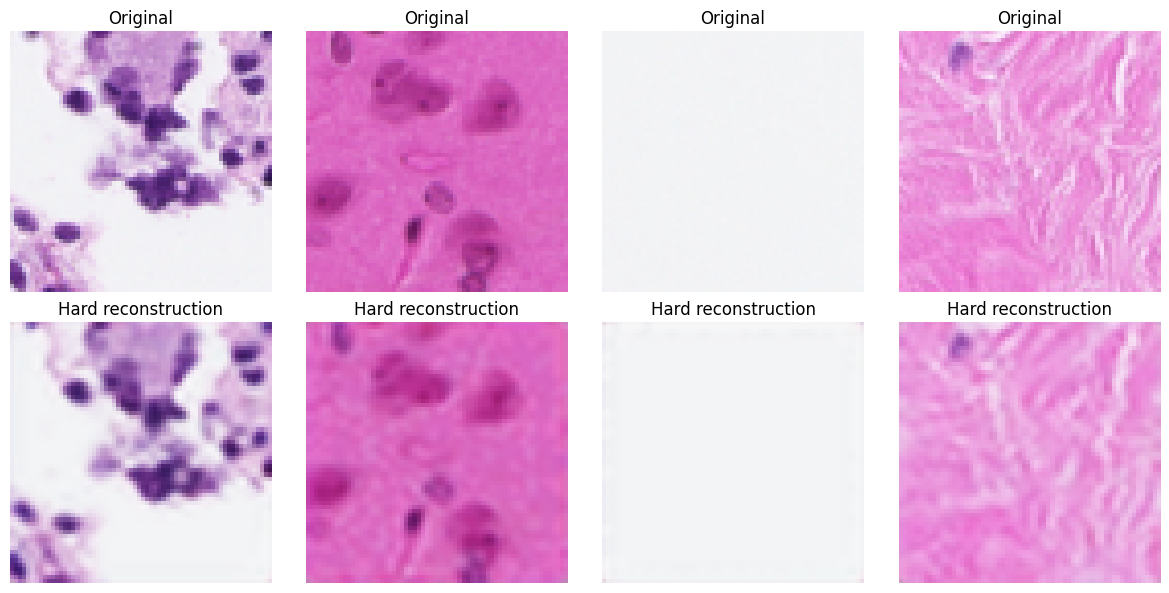

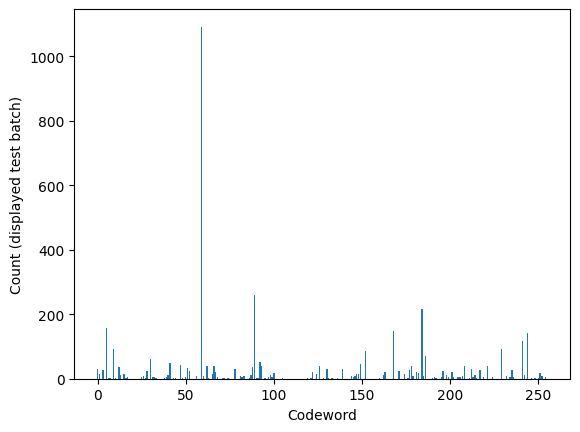

Used codewords in displayed batch: 132 / 256


In [11]:
SELECTED_CHECKPOINT = RUN_DIR / 'best.pt'  # Replace with a validation-selected sweep checkpoint if needed.
model, checkpoint = load_checkpoint(SELECTED_CHECKPOINT, soft_quantize, DEVICE)
test_metrics = evaluate(model, loaders['test'], DEVICE, checkpoint['train_config']['rate_weight'])
print('Selected epoch:', checkpoint['epoch'])
print(json.dumps(test_metrics, indent=2))
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(dict(checkpoint=str(SELECTED_CHECKPOINT), **test_metrics), indent=2))
images = next(iter(loaders['test']))[:4].to(DEVICE)
with torch.no_grad():
    result = model(images)
fig, axes = plt.subplots(2, len(images), figsize=(3*len(images), 6), squeeze=False)
for i in range(len(images)):
    axes[0, i].imshow(images[i].cpu().permute(1,2,0)); axes[0, i].set_title('Original')
    axes[1, i].imshow(result['reconstruction'][i].cpu().permute(1,2,0)); axes[1, i].set_title('Hard reconstruction')
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout(); plt.savefig(RUN_DIR / 'reconstructions.png'); plt.show()
counts = torch.bincount(result['indices'].flatten(), minlength=model.config['codebook_size']).cpu()
plt.bar(range(len(counts)), counts); plt.xlabel('Codeword'); plt.ylabel('Count (displayed test batch)'); plt.show()
print('Used codewords in displayed batch:', int((counts > 0).sum()), '/', len(counts))

## Step 8 — Save a compressed file and compare actual sizes with JPEG

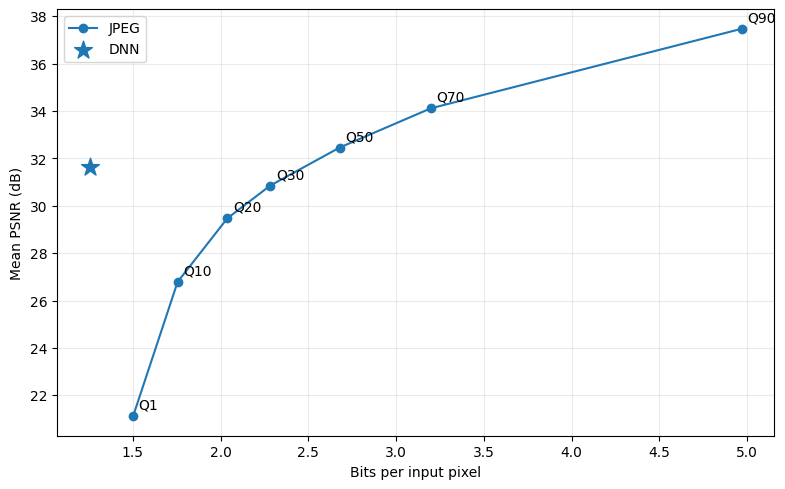

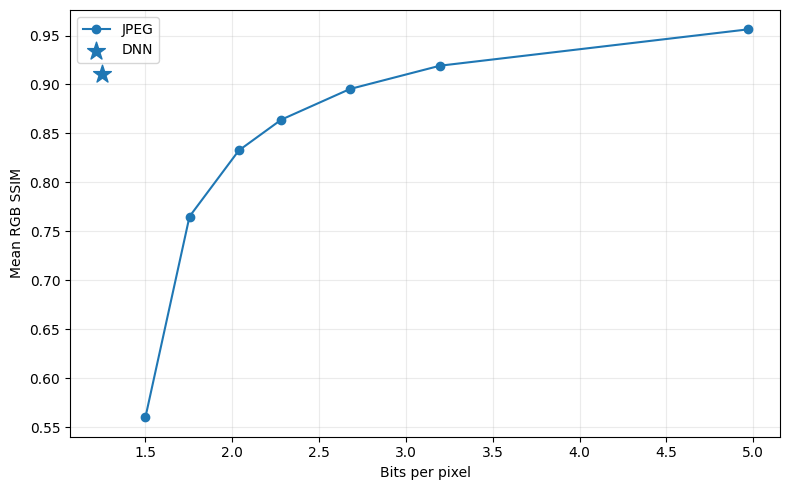

DNN         256 images | 1.2531 bpp | 31.64 dB | SSIM=0.9112
JPEG Q1     256 images | 1.5013 bpp | 21.11 dB | SSIM=0.5599
JPEG Q10    256 images | 1.7551 bpp | 26.79 dB | SSIM=0.7651
JPEG Q20    256 images | 2.0389 bpp | 29.48 dB | SSIM=0.8326
JPEG Q30    256 images | 2.2831 bpp | 30.86 dB | SSIM=0.8640
JPEG Q50    256 images | 2.6785 bpp | 32.46 dB | SSIM=0.8954
JPEG Q70    256 images | 3.1971 bpp | 34.12 dB | SSIM=0.9192
JPEG Q90    256 images | 4.9683 bpp | 37.47 dB | SSIM=0.9563
DNN coding modes: {'zlib': 256, 'arithmetic-left': 0, 'arithmetic-up': 0}
DNN bpp counts compressed latent bytes only; JPEG bpp counts complete JPEG bytes.
Codewords used over evaluation set: 221/256
DNN estimated bpp: 1.9412794634699821
Rates may not overlap: this is not a matched-bitrate superiority claim.
Shared checkpoint bytes (excluded from bpp): 790418


In [12]:
import comparison
compare_jpeg = partial(comparison.compare_jpeg, **student_metrics)
visualize_decoded = partial(comparison.visualize_decoded, **student_metrics)
COMPARISON_DIR = RUN_DIR / 'jpeg_comparison'
comparison_summary, comparison_examples = compare_jpeg(
    model, loaders['test'], DEVICE, COMPARISON_DIR,
    qualities=(1, 10, 20, 30, 50, 70, 90), examples=4,
)
print('Shared checkpoint bytes (excluded from bpp):', Path(SELECTED_CHECKPOINT).stat().st_size)


Evaluated Baseline on 256 test images
Evaluated lambda=0 on 256 test images
Evaluated lambda=0.001 on 256 test images
Evaluated lambda=0.01 on 256 test images
Evaluated K=32 on 256 test images
Evaluated K=64 on 256 test images
Evaluated K=128 on 256 test images
Baseline     file BPP=1.517 | payload BPP=1.253 | PSNR=31.63 | SSIM=0.9109
lambda=0     file BPP=1.558 | payload BPP=1.294 | PSNR=31.62 | SSIM=0.9109
lambda=0.001 file BPP=1.479 | payload BPP=1.215 | PSNR=31.47 | SSIM=0.9084
lambda=0.01  file BPP=1.180 | payload BPP=0.917 | PSNR=30.88 | SSIM=0.9017
K=32         file BPP=1.266 | payload BPP=1.003 | PSNR=29.70 | SSIM=0.8881
K=64         file BPP=1.441 | payload BPP=1.178 | PSNR=30.55 | SSIM=0.8981
K=128        file BPP=1.762 | payload BPP=1.498 | PSNR=31.11 | SSIM=0.9041
JPEG Q1      file BPP=1.501 | payload BPP=1.501 | PSNR=21.11 | SSIM=0.5599
JPEG Q5      file BPP=1.590 | payload BPP=1.590 | PSNR=24.15 | SSIM=0.6765
JPEG Q10     file BPP=1.755 | payload BPP=1.755 | PSNR=26.79 | 

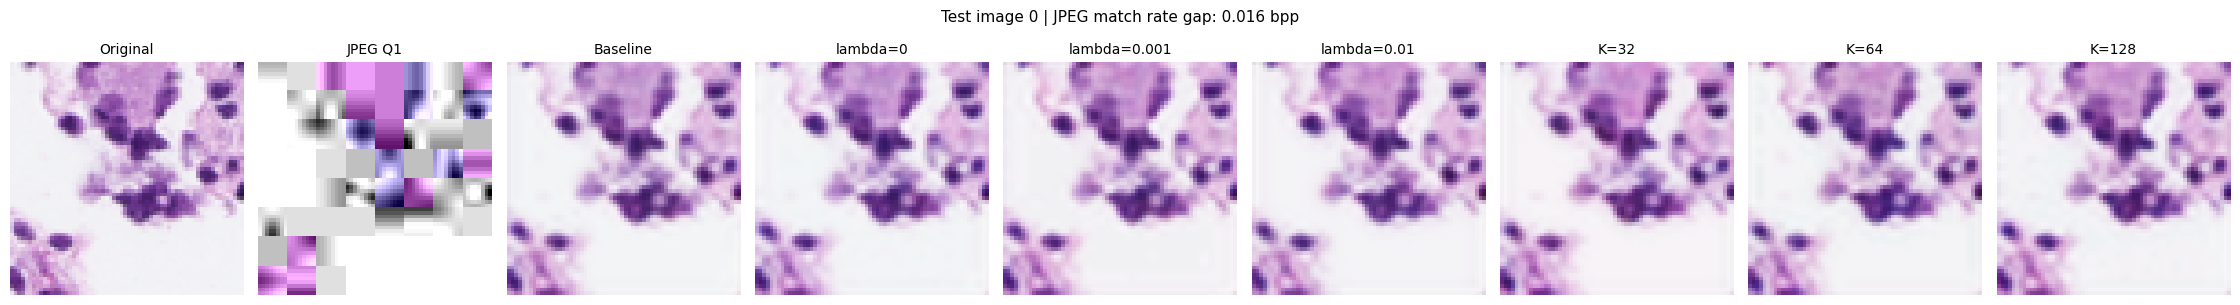

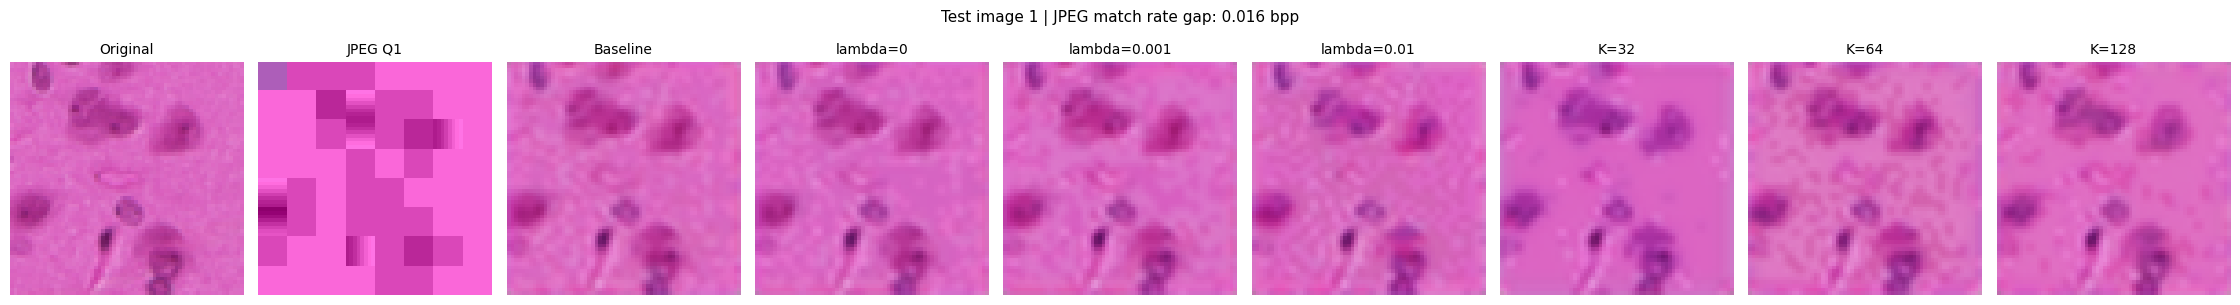

Question 4 results saved in: C:\Users\anest\Desktop\UofT\Digital Image Processing\Project B\Project_B_Starter_Code\ECE1512_Student_Project\dnn_compression_notebook\runs\solution_larger_20261123_050247_803626\q4_ablation_results


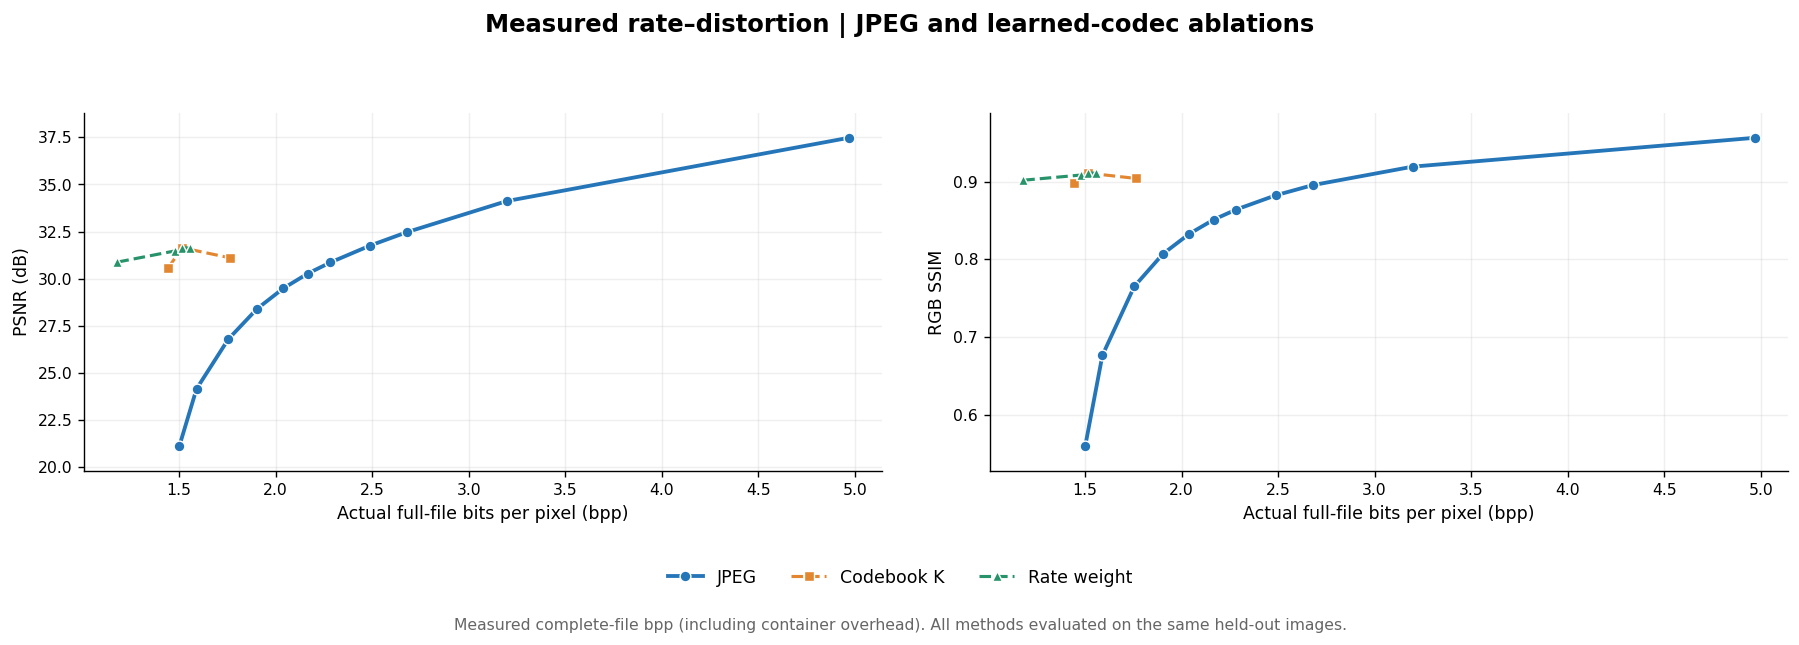

Saved improved figure: c:\Users\anest\Desktop\UofT\Digital Image Processing\Project B\Project_B_Starter_Code\ECE1512_Student_Project\dnn_compression_notebook\runs\solution_larger_20261123_050247_803626\q4_ablation_results\q4_measured_rate_distortion_overview.png


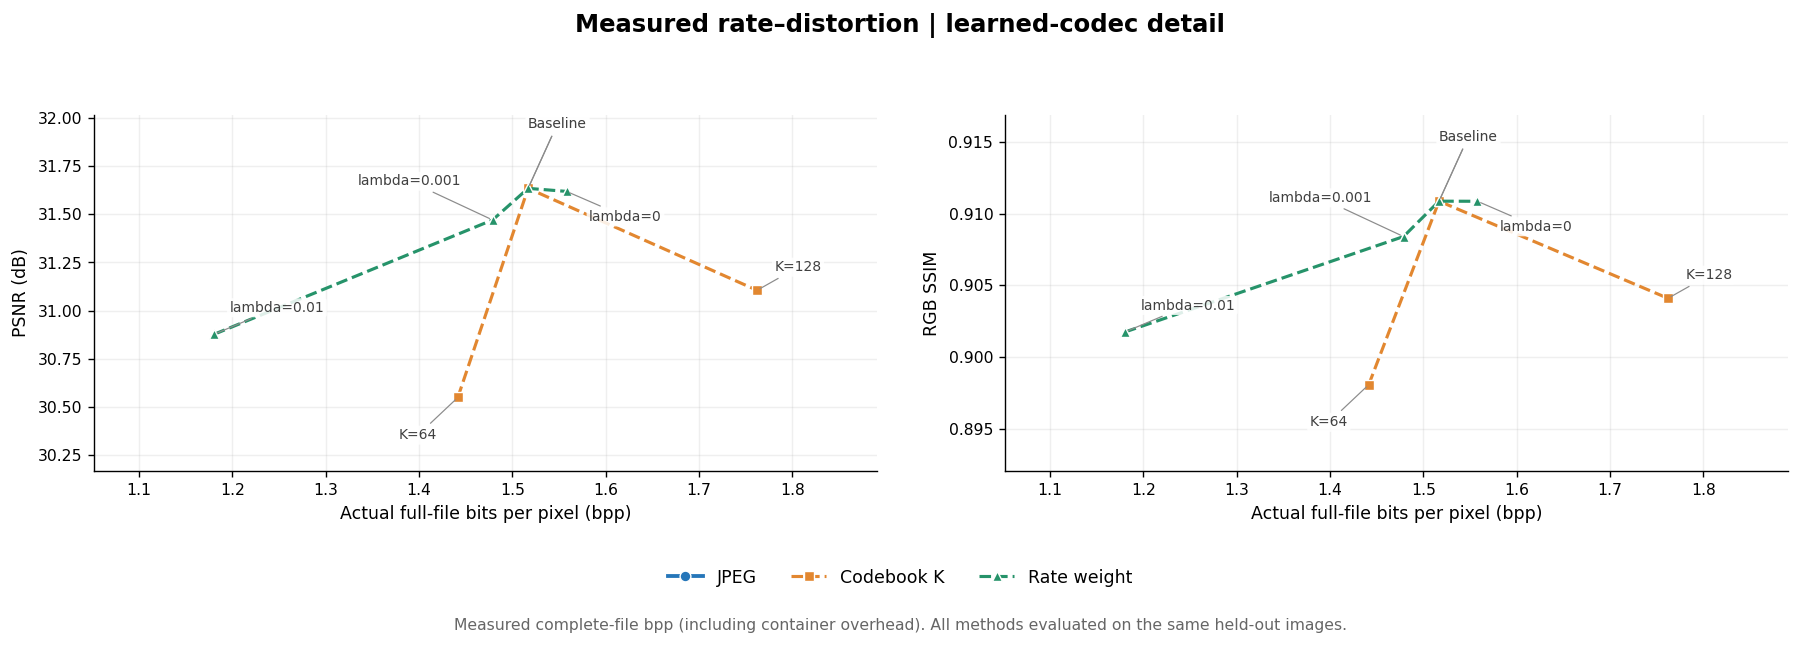

Saved improved figure: c:\Users\anest\Desktop\UofT\Digital Image Processing\Project B\Project_B_Starter_Code\ECE1512_Student_Project\dnn_compression_notebook\runs\solution_larger_20261123_050247_803626\q4_ablation_results\q4_measured_rate_distortion_zoom.png


In [ ]:

# QUESTION 4 — FINAL MEASURED RATE-DISTORTION EVALUATION
# Executes the original q4_evaluation_cell.py unchanged.
# Captures its PSNR/SSIM plot data for cleaner visualization.
# The original q4_evaluation_cell.py must be in PROJECT_DIR.

from collections import OrderedDict

_q4_original_show = plt.show
_q4_rd_curves = OrderedDict()


def _capture_q4_rd_plot(*args, **kwargs):
    fig = plt.gcf()

    if len(fig.axes) == 1:
        ax = fig.axes[0]
        xlabel = ax.get_xlabel().lower()
        ylabel = ax.get_ylabel().lower()

        metric = ('psnr' if 'psnr' in ylabel else 'ssim' if 'ssim' in ylabel else None)

        if (metric and 'bits per pixel' in xlabel and 'full' in xlabel):
            curves = []

            for line in ax.lines:
                if line.get_label().startswith('_'):
                    continue
                x_data = np.asarray(line.get_xdata(), dtype=float).ravel()
                y_data = np.asarray(line.get_ydata(), dtype=float).ravel()
                good = np.isfinite(x_data) & np.isfinite(y_data)
                if good.any():
                    curves.append(
                        dict(label=line.get_label(), x=x_data[good].copy(),y=y_data[good].copy()))
            annotations = []
            for label in ax.texts:
                if hasattr(label, 'xy'):
                    xy = tuple(float(v) for v in label.xy)
                    if len(xy) == 2 and np.isfinite(xy).all():
                        annotations.append(dict(label=label.get_text(),xy=xy))

            if curves:
                _q4_rd_curves[metric] = dict(curves=curves,annotations=annotations)
                plt.close(fig)
                return

    return _q4_original_show(*args, **kwargs)


# ==========================================================
# RUN THE ORIGINAL EVALUATION
# ==========================================================

try:
    plt.show = _capture_q4_rd_plot
    evaluation_code = (PROJECT_DIR / 'q4_evaluation_cell.py').read_text(encoding='utf-8')
    exec(compile(evaluation_code, 'q4_evaluation_cell.py','exec'))
finally:
    plt.show = _q4_original_show


# ==========================================================
# IMPROVED MEASURED RATE-DISTORTION PLOTS
# ==========================================================

if {'psnr', 'ssim'} <= set(_q4_rd_curves):
    _q4_styles = {'jpeg': dict(color='#2576B9',marker='o',linestyle='-',lw=2.2),'codebook': dict(color='#E28730',marker='s',linestyle='--',lw=1.8),'rate': dict(color='#26936A',marker='^',linestyle='--',lw=1.8)}

    def _q4_style_for(label):
        lower = label.lower()
        kind = ('jpeg' if 'jpeg' in lower else 'codebook' if 'codebook' in lower else 'rate')
        return _q4_styles[kind]

    def _draw_q4_panel(ax, metric, zoom=False):
        info = _q4_rd_curves[metric]

        for series in info['curves']:
            style = dict(_q4_style_for(series['label']))
            ax.plot(series['x'],series['y'],label=series['label'],ms=6.2,markeredgecolor='white',markeredgewidth=0.8,**style)

        ylabel = ('PSNR (dB)' if metric == 'psnr' else 'RGB SSIM')

        ax.set_ylabel(ylabel)
        ax.set_xlabel('Actual full-file bits per pixel (bpp)')
        ax.grid(alpha=0.20)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(labelsize=9)

        if zoom:
            # Zoom uses the actual non-JPEG coordinates.
            learned = [series for series in info['curves'] if 'jpeg' not in series['label'].lower()]

            if learned:
                xx = np.concatenate([s['x'] for s in learned])
                yy = np.concatenate([s['y'] for s in learned])
                xpad = max((xx.max() - xx.min()) * 0.22,0.12)
                ypad = max((yy.max() - yy.min()) * 0.35, 0.35 if metric == 'psnr' else 0.006)

                ax.set_xlim(xx.min() - xpad, xx.max() + xpad)
                ax.set_ylim(yy.min() - ypad, yy.max() + ypad)

                # Separate labels with offset callouts.
                offsets = {'baseline': (0, 35),'0.001': (-18, 20), '0.01': (9, 13),'0.0': (0, -25),'k=32': (-15, -21),'k=64': (-12, -24),'k=128': (10, 11)}

                for i, item in enumerate(info['annotations']):
                    name = item['label'].strip()
                    x, y = item['xy']

                    if not name or not (xx.min() - 0.02 <= x <= xx.max() + 0.02):
                        continue
                    low = name.lower().replace(' ', '')
                    shift = next((v for k, v in offsets.items() if k in low), [(9, 14), (-20, -21), (13, -17), (11, 25)][i % 4])
                    ax.annotate(name, xy=(x, y),xytext=shift, textcoords='offset points', ha='left' if shift[0] >= 0 else 'right', fontsize=8, color='0.25', bbox=dict( boxstyle='round,pad=0.18', fc='white',ec='none', alpha=0.86), arrowprops=dict(arrowstyle='-',lw=0.7,color='0.55'), clip_on=False)

        else:
            ax.margins(x=0.045, y=0.08)


    # ==========================================================
    # SAVE OVERVIEW AND ZOOMED FIGURES
    # ==========================================================

    _q4_dir = RUN_DIR / 'q4_ablation_results'
    _q4_dir.mkdir(parents=True, exist_ok=True)

    for zoom, title, stem in (
        (False,'Measured rate–distortion | JPEG and learned-codec ablations','q4_measured_rate_distortion_overview'),
        (True,'Measured rate–distortion | learned-codec detail','q4_measured_rate_distortion_zoom' ) ):
        fig, axes = plt.subplots(1, 2,figsize=(14.5, 5.1),dpi=125)

        for ax, metric in zip(axes, ('psnr', 'ssim')):
            _draw_q4_panel(ax, metric, zoom=zoom)

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles,labels,loc='lower center', ncol=3,frameon=False,bbox_to_anchor=(0.5, 0.055),fontsize=10)
        fig.suptitle(title,fontsize=14, weight='bold')
        fig.text(0.5, 0.012,'Measured complete-file bpp ' '(including container overhead). ''All methods evaluated on the same held-out images.',ha='center',fontsize=9,color='0.4')
        fig.tight_layout(rect=(0, 0.15, 1, 0.92), w_pad=2.7)
        fig.savefig( _q4_dir / (stem + '.png'),dpi=200, bbox_inches='tight')
        fig.savefig(_q4_dir / (stem + '.pdf'),bbox_inches='tight')
        _q4_original_show()
        print('Saved improved figure:',_q4_dir / (stem + '.png'))

else:
    print('NOTE: Could not identify both PSNR and SSIM ''full-file-bpp plots. ''The original Q4 evaluator still ran; ''review its output and axis labels.')


## Optional dense JPEG comparison

Set `RUN_DENSE_JPEG = True` to recompute JPEG qualities 1–95 using your PSNR and SSIM implementations on the selected test loader. This is evaluation after model selection.


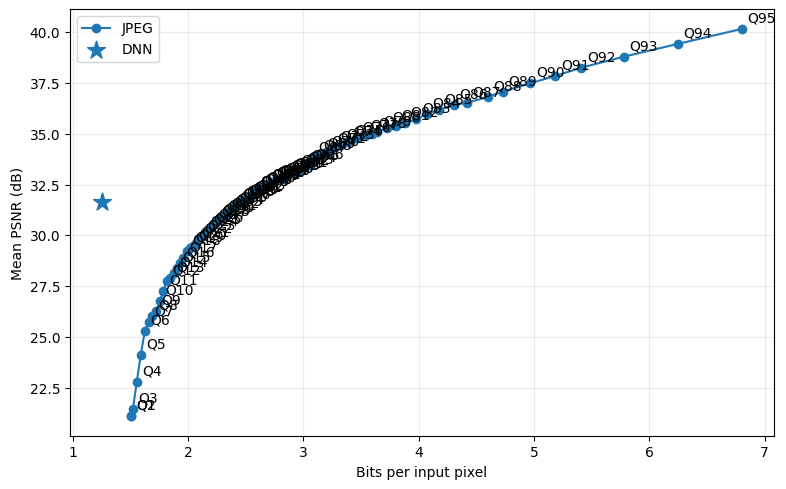

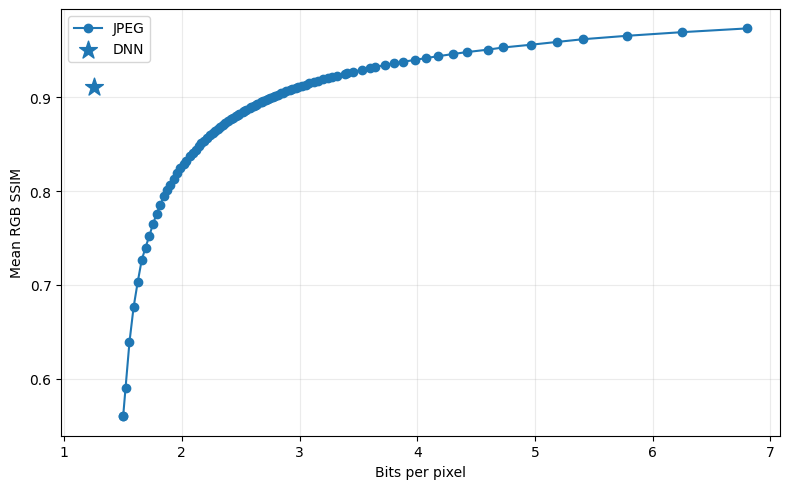

DNN         256 images | 1.2531 bpp | 31.64 dB | SSIM=0.9112
JPEG Q1     256 images | 1.5013 bpp | 21.11 dB | SSIM=0.5599
JPEG Q2     256 images | 1.5015 bpp | 21.12 dB | SSIM=0.5603
JPEG Q3     256 images | 1.5215 bpp | 21.46 dB | SSIM=0.5899
JPEG Q4     256 images | 1.5550 bpp | 22.79 dB | SSIM=0.6392
JPEG Q5     256 images | 1.5902 bpp | 24.15 dB | SSIM=0.6765
JPEG Q6     256 images | 1.6250 bpp | 25.30 dB | SSIM=0.7031
JPEG Q7     256 images | 1.6585 bpp | 25.73 dB | SSIM=0.7263
JPEG Q8     256 images | 1.6913 bpp | 26.03 dB | SSIM=0.7399
JPEG Q9     256 images | 1.7234 bpp | 26.27 dB | SSIM=0.7523
JPEG Q10    256 images | 1.7551 bpp | 26.79 dB | SSIM=0.7651
JPEG Q11    256 images | 1.7861 bpp | 27.26 dB | SSIM=0.7762
JPEG Q12    256 images | 1.8161 bpp | 27.78 dB | SSIM=0.7856
JPEG Q13    256 images | 1.8469 bpp | 27.89 dB | SSIM=0.7944
JPEG Q14    256 images | 1.8742 bpp | 28.17 dB | SSIM=0.8013
JPEG Q15    256 images | 1.9036 bpp | 28.40 dB | SSIM=0.8069
JPEG Q16    256 images |

In [14]:
RUN_DENSE_JPEG = True  # Optional: expensive evaluation over all 95 qualities.
if RUN_DENSE_JPEG:
    dense_summary, _ = compare_jpeg(
        model, loaders['test'], DEVICE, RUN_DIR / 'dense_jpeg_comparison',
        qualities=tuple(range(1, 96)), examples=0,
    )


## Final visualization — the decoded image
Decode the actual saved DNN bitstream, and display it beside the original and JPEG Q10. Labels show each actual file bitrate and PSNR; error maps share a color scale.


Decoded from: c:\Users\anest\Desktop\UofT\Digital Image Processing\Project B\Project_B_Starter_Code\ECE1512_Student_Project\dnn_compression_notebook\runs\solution_larger_20261123_050247_803626\jpeg_comparison\image_0.ecvq
Saved: c:\Users\anest\Desktop\UofT\Digital Image Processing\Project B\Project_B_Starter_Code\ECE1512_Student_Project\dnn_compression_notebook\runs\solution_larger_20261123_050247_803626\jpeg_comparison\decoded_image.png


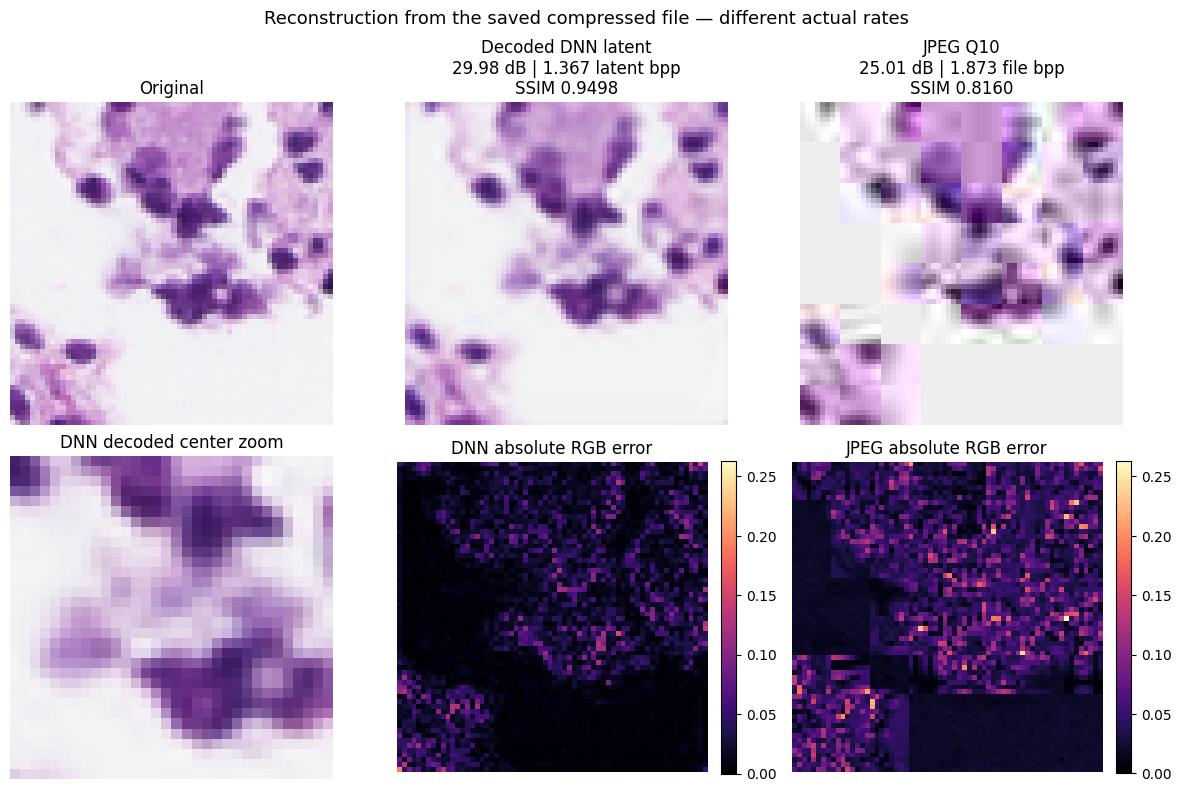

In [15]:
decoder_model, _ = load_checkpoint(SELECTED_CHECKPOINT, soft_quantize, DEVICE)
decoded_image = visualize_decoded(
    decoder_model, COMPARISON_DIR / 'image_0.ecvq',
    COMPARISON_DIR / 'image_0_original.png', COMPARISON_DIR, jpeg_quality=10,
)
